In [1]:
from html import escape
from pathlib import Path
from time import monotonic

import matplotlib.pyplot as plt
import numpy as np
import torch
from PIL import Image
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

from custom_cnn import CustomCNN
from resnet import ResNet18
from IPython.display import HTML, Markdown, display


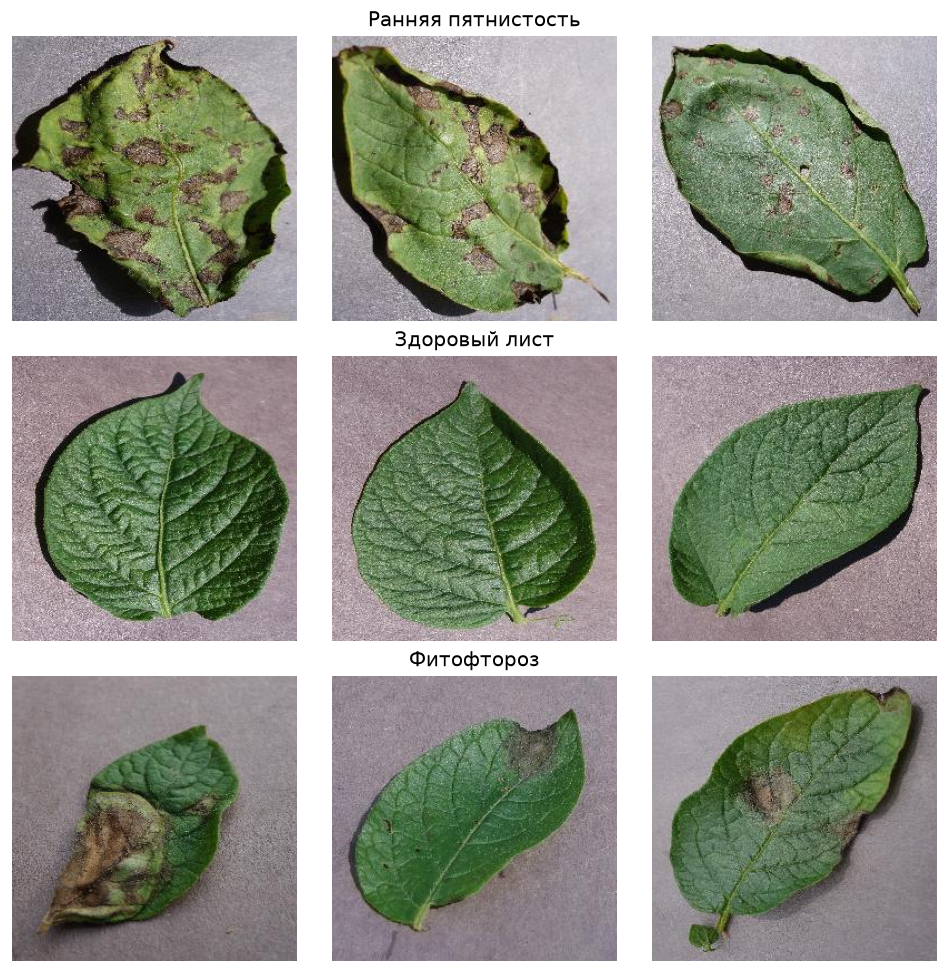

In [2]:
dataset_dir = Path("datasets") / "plantvillage-potato"
labels = {
    "Potato___Early_blight": "Ранняя пятнистость",
    "Potato___healthy": "Здоровый лист",
    "Potato___Late_blight": "Фитофтороз",
}

fig, axes = plt.subplots(3, 3, figsize=(8, 8), layout="constrained")

for row, (folder, label) in zip(axes, labels.items()):
    files = sorted((dataset_dir / folder).glob("*.jpg", case_sensitive=False))[:3]
    for ax, file in zip(row, files):
        ax.imshow(plt.imread(file))
        ax.axis("off")
    row[1].set_title(label)

plt.show()


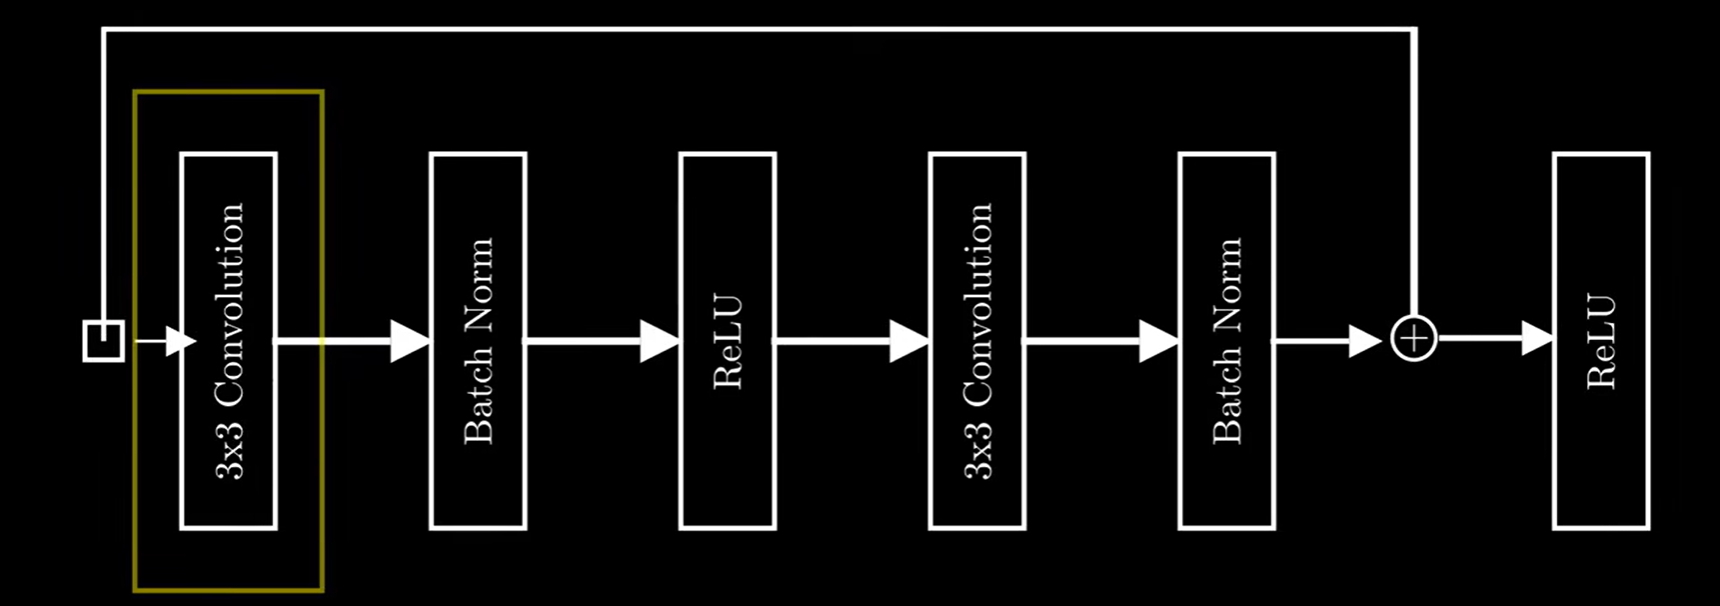

### Зачем в ResNet обходная связь

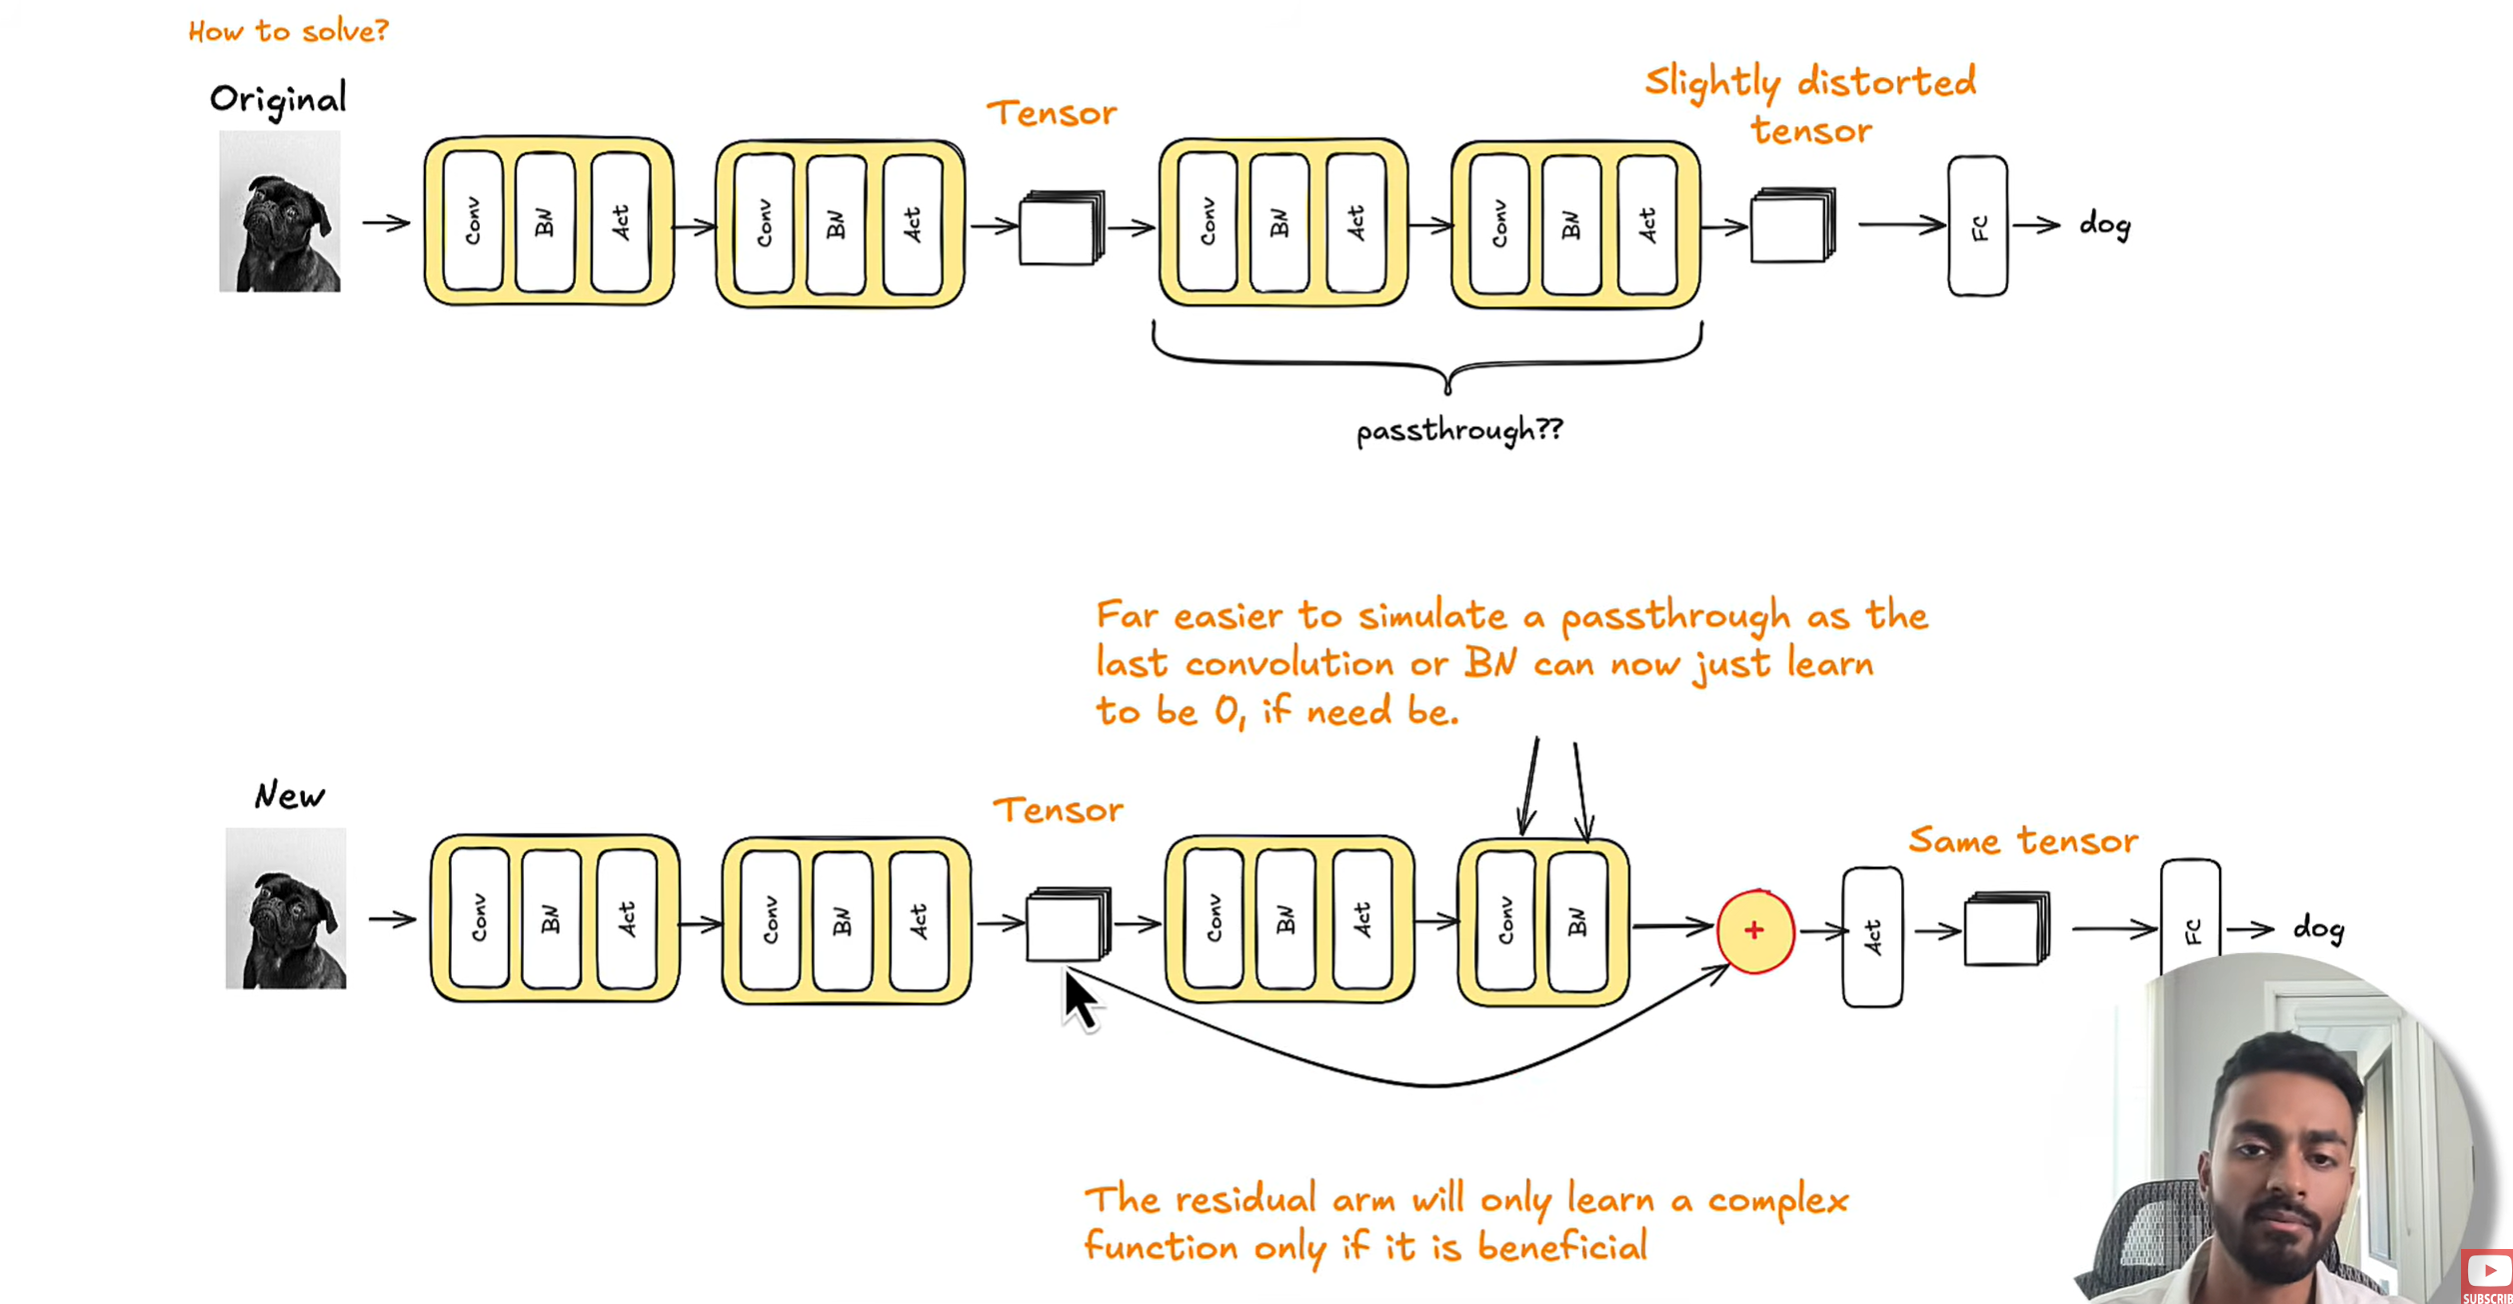

На рисунке: сверху — обычная цепочка слоёв, снизу — блок с обходной связью. Скриншот предоставлен пользователем; [видео CodeEmporium о ResNet](https://www.youtube.com/watch?v=gyhCfjixLV0).


При увеличении глубины обычную сеть может стать труднее оптимизировать: дополнительные слои не всегда удаётся обучить даже просто сохранять уже полезные признаки. Это может повысить ошибку на обучающей выборке — проблема не обязательно связана с переобучением.


В ResNet блок обучает поправку $F(x)$ к своему входу $x$. При совпадении размеров тензоров перед заключительной активацией получаем

$$y=x+F(x).$$

Здесь $x$ — вход блока, обычно карты признаков предыдущих слоёв, а не исходная фотография. Если дополнительное преобразование не нужно, достаточно приблизить $F(x)$ к нулю: обходная связь сохранит вход.


Такое представление часто облегчает оптимизацию: блоку проще выучить небольшую поправку к признакам. Обходная связь также создаёт прямой путь для градиента при обратном распространении ошибки. Это не гарантирует нахождения глобального минимума.


В нашей реализации после суммы применяется ReLU: $y=\operatorname{ReLU}(F(x)+x)$. При $F(x)=0$ вход сохраняется точно, если он неотрицателен, как после предыдущего ReLU. Если размер карты или число каналов меняется, обходная ветвь использует проекцию $P(x)$ — свёртку $1\times1$ с BatchNorm; складываются $F(x)$ и $P(x)$.

Источник пояснения: [He et al., Deep Residual Learning for Image Recognition](https://arxiv.org/abs/1512.03385).


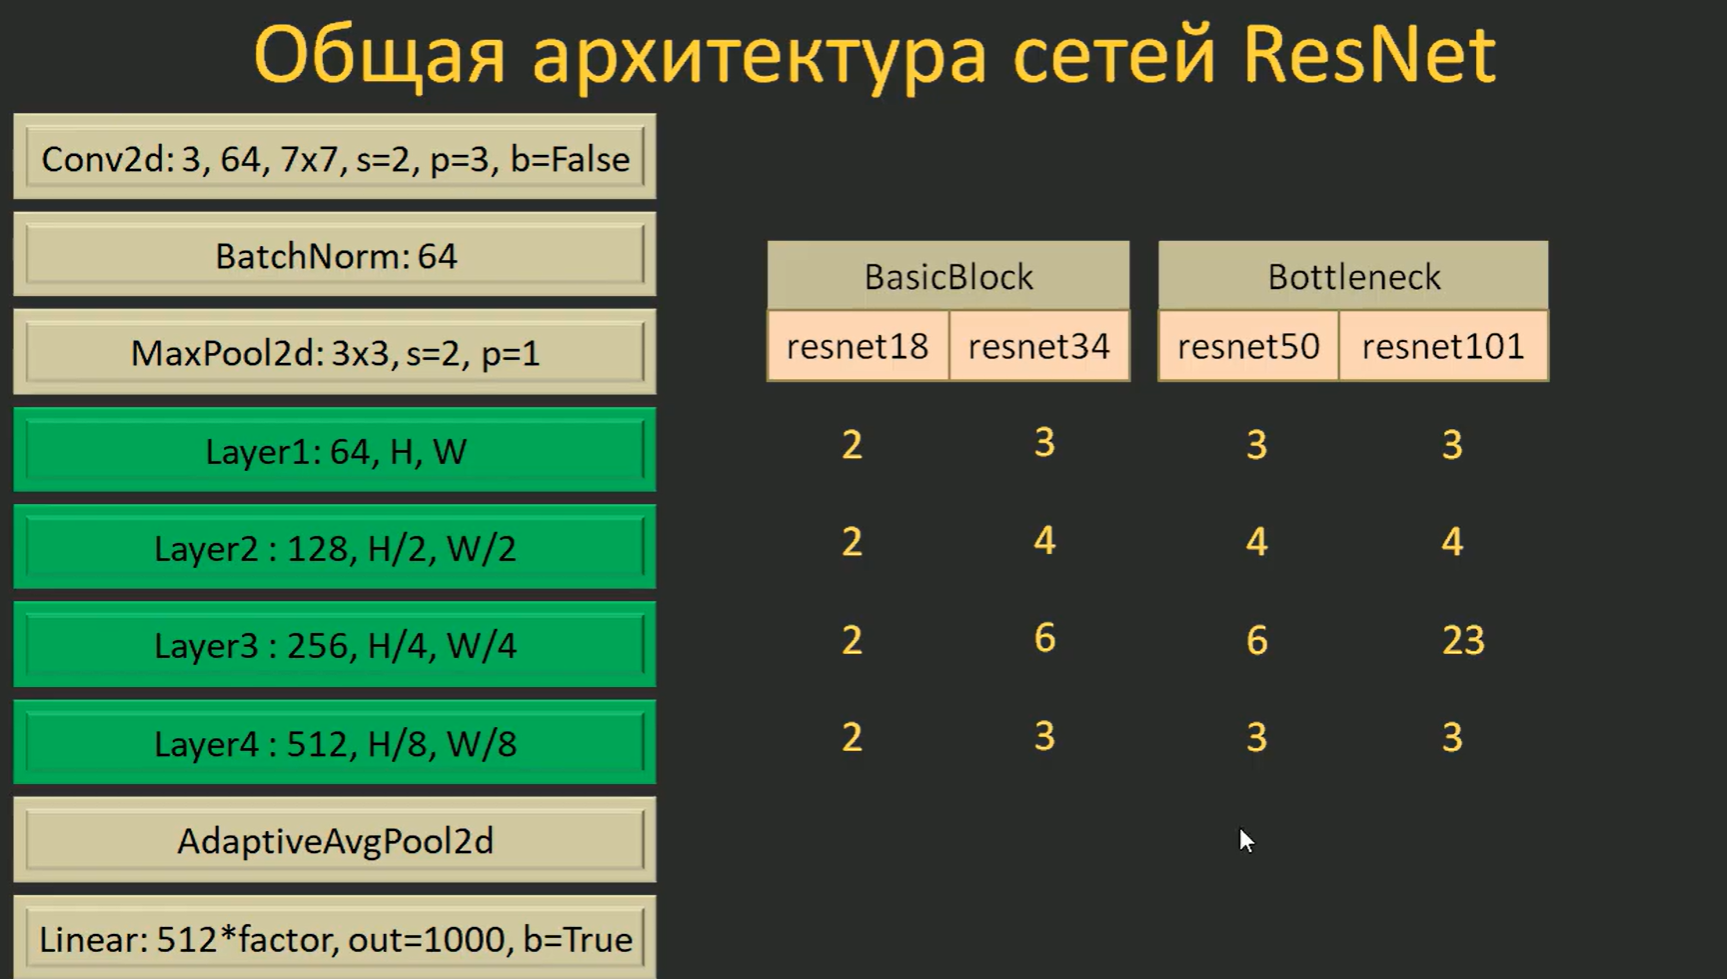

На схеме 1000 классов ImageNet. В нашей задаче линейный слой выдаёт три логита.


## 2. Обучение моделей
Обе модели используют одно разбиение. Веса классов одинаковы в обоих прогонах и учитывают дисбаланс. Тестовую выборку откладываем для итоговой оценки.

### Основная метрика

$$
R_{\mathrm{weighted}}(\alpha)=
\frac{R_{\text{альтернариоз}}+\alpha R_{\text{фитофтороз}}}{1+\alpha}.
$$

$R_c$ — доля правильно распознанных изображений среди всех изображений класса $c$. По умолчанию $\alpha=2$, поэтому recall фитофтороза влияет на итог вдвое сильнее. Здоровый класс в формулу не входит. Precision и число ложных тревог показываем отдельно. Функция обучения — взвешенная кросс-энтропия.


In [3]:
torch.manual_seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

image_size = 64
batch_size = 32
train_ids, val_ids, test_ids = [], [], []
images, targets = [], []

# Делим каждый класс отдельно в пропорции 70/15/15
for class_id, folder in enumerate(labels):
    files = sorted((dataset_dir / folder).glob("*.jpg", case_sensitive=False))
    # randperm перемешивает индексы внутри класса
    indices = torch.randperm(len(files)) + len(images)
    train_end = int(0.70 * len(files))
    val_end = int(0.85 * len(files))
    train_ids.extend(indices[:train_end].tolist())
    val_ids.extend(indices[train_end:val_end].tolist())
    test_ids.extend(indices[val_end:].tolist())

    for file in files:
        with Image.open(file) as image:
            image = image.convert("RGB").resize((image_size, image_size))
            images.append(np.array(image))
        targets.append(class_id)

# permute переносит каналы из последней оси на вторую - N×H×W×C → N×C×H×W
images = torch.from_numpy(np.stack(images)).permute(0, 3, 1, 2)
targets = torch.tensor(targets)
num_classes = len(labels)

train_data = TensorDataset(images[train_ids], targets[train_ids])
val_data = TensorDataset(images[val_ids], targets[val_ids])
# DataLoader собирает батчи и перемешивает обучающие примеры перед каждой эпохой
train_loader = DataLoader(train_data, batch_size=batch_size, shuffle=True)
val_loader = DataLoader(val_data, batch_size=batch_size)

# повышаем вес редкого класса, чтобы ошибки на здоровых листьях не терялись
class_counts = torch.bincount(targets[train_ids])
class_weights = (len(train_ids) / (num_classes * class_counts)).to(device)
criterion = nn.CrossEntropyLoss(weight=class_weights, reduction="sum")

print(f"Устройство: {device} | Обучение: {len(train_ids)} | Валидация: {len(val_ids)} | Тест: {len(test_ids)}")


Устройство: cuda | Обучение: 1506 | Валидация: 323 | Тест: 323


In [4]:
def weighted_disease_recall(recall, alpha=2):
    # Индексы 0 и 2 - альтернариоз и фитофтороз в порядке labels
    return (recall[0] + alpha * recall[2]) / (1 + alpha)


def run_epoch(model, loader, optimizer=None, augment=False):
    training = optimizer is not None

    # В режиме оценки BatchNorm использует накопленную статистику
    model.train(training)
    total_loss, total_weight = 0.0, 0.0
    correct = torch.zeros(num_classes, dtype=torch.long, device=device)
    counts = torch.zeros_like(correct)

    # На валидации отключаем вычисление градиентов
    with torch.set_grad_enabled(training):
        for x, y in loader:
            x = x.to(device).float() / 255
            y = y.to(device)

            # Выбираем случайные изображения в батче и отражаем их по ширине
            if training and augment:
                flip = torch.rand(len(x), device=device) < 0.5
                x[flip] = x[flip].flip(-1)

                # rot90 поворачивает квадратные изображения на 0, 90, 180 или 270 градусов
                turns = torch.randint(0, 4, (len(x),), device=device)
                for k in (1, 2, 3):
                    mask = turns == k
                    x[mask] = x[mask].rot90(k, dims=(-2, -1))

                # Меняем яркость каждого изображения в пределах 10% и сохраняем диапазон [0, 1]
                brightness = 0.9 + 0.2 * torch.rand(len(x), 1, 1, 1, device=device)
                x = (x * brightness).clamp(0, 1)

            # CrossEntropyLoss принимает логиты и индексы правильных классов
            logits = model(x)
            loss = criterion(logits, y)
            weight = class_weights[y].sum()

            if training:
                # Сбрасываем градиенты, считаем новые и обновляем веса
                optimizer.zero_grad()
                (loss / weight).backward()
                optimizer.step()

            # Суммируем взвешенную ошибку по батчам для среднего за эпоху
            total_loss += loss.item()
            total_weight += weight.item()

            # argmax выбирает класс с наибольшим логитом
            matches = logits.argmax(dim=1) == y

            # bincount считает число примеров и верных ответов каждого класса
            counts += torch.bincount(y, minlength=num_classes)
            correct += torch.bincount(y[matches], minlength=num_classes)

    # Recall каждого класса - доля верных ответов среди его примеров
    recall = correct / counts
    return total_loss / total_weight, recall.tolist()


In [5]:
epochs = 80
alpha = 2  # - относительная важность фитофтороза
checkpoint_dir = Path("checkpoints")
checkpoint_dir.mkdir(exist_ok=True)


def fit(model_class, augment=False, alpha=2):
    # Повторно задаём seed для одинаковых начальных весов в двух прогонах
    torch.manual_seed(42)
    model = model_class(num_classes=num_classes).to(device)

    optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
    history = []
    best_recall = -1.0
    name = model_class.__name__
    suffix = "_augmented" if augment else "_baseline"
    checkpoint = checkpoint_dir / f"{name}{suffix}.pt"

    for epoch in range(1, epochs + 1):
        train_loss, train_by_class = run_epoch(model, train_loader, optimizer, augment=augment)
        val_loss, valid_by_class = run_epoch(model, val_loader)
        train_recall = weighted_disease_recall(train_by_class, alpha)
        val_recall = weighted_disease_recall(valid_by_class, alpha)
        history.append((train_loss, train_recall, val_loss, val_recall))

        # При равном recall сохраняем более раннюю эпоху.
        if val_recall > best_recall:
            best_recall = val_recall
            torch.save({"weights": model.state_dict(), "epoch": epoch}, checkpoint)
        print(
            f"{name} | {epoch:2d} | train loss {train_loss:.3f}, weighted disease recall {train_recall:.1%}"
            f" | valid loss {val_loss:.3f}, weighted disease recall {val_recall:.1%}",
            flush=True,
        )

    return history


In [6]:
def plot_history(history):
    fig, axes = plt.subplots(2, 2, figsize=(11, 7), layout="constrained")
    for row, (name, rows) in zip(axes, history.items()):
        train_loss, train_recall, val_loss, val_recall = zip(*rows)
        steps = range(1, len(rows) + 1)

        row[0].plot(steps, train_loss, label="train")
        row[0].plot(steps, val_loss, "--", label="valid")
        row[0].set(title=name, xlabel="Epoch", ylabel="Loss")
        row[0].legend()

        row[1].plot(steps, train_recall, label="train")
        row[1].plot(steps, val_recall, "--", label="valid")
        row[1].set(title=name, xlabel="Epoch", ylabel="Weighted disease recall", ylim=(0, 1))
        row[1].legend()

    plt.show()


### Базовый прогон
Обучаем обе модели 80 эпох. По графикам смотрим, как меняются ошибка и взвешенный recall болезней на обучении и валидации.

CustomCNN |  1 | train loss 1.096, weighted disease recall 32.6% | valid loss 1.085, weighted disease recall 33.3%
CustomCNN |  2 | train loss 1.082, weighted disease recall 41.3% | valid loss 1.072, weighted disease recall 33.3%
CustomCNN |  3 | train loss 1.045, weighted disease recall 62.4% | valid loss 0.992, weighted disease recall 70.0%
CustomCNN |  4 | train loss 0.930, weighted disease recall 82.6% | valid loss 0.856, weighted disease recall 93.1%
CustomCNN |  5 | train loss 0.814, weighted disease recall 86.9% | valid loss 0.763, weighted disease recall 73.3%
CustomCNN |  6 | train loss 0.740, weighted disease recall 80.3% | valid loss 0.891, weighted disease recall 86.0%
CustomCNN |  7 | train loss 0.723, weighted disease recall 82.0% | valid loss 1.047, weighted disease recall 43.1%
CustomCNN |  8 | train loss 0.728, weighted disease recall 78.9% | valid loss 0.693, weighted disease recall 74.9%
CustomCNN |  9 | train loss 0.645, weighted disease recall 83.6% | valid loss 0.

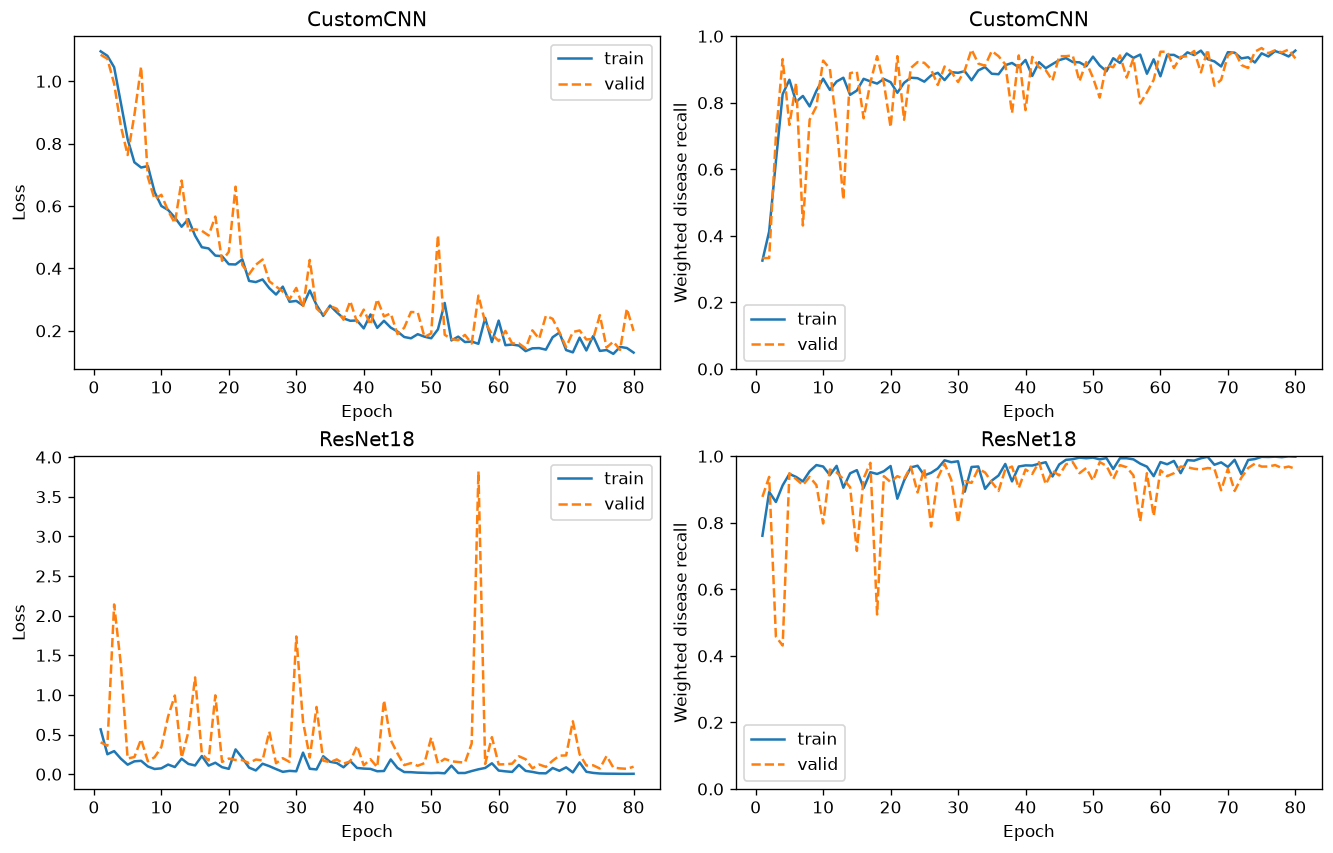

In [7]:
start = monotonic()
models = (CustomCNN, ResNet18)

baseline_history = {model.__name__: fit(model, alpha=alpha) for model in models}
plot_history(baseline_history)


На итоговом графике сравниваем сохранённые веса лучших эпох каждого прогона.

### Борьба с переобучением
На train случайно отражаем изображения по горизонтали с вероятностью 0,5, поворачиваем на 0°, 90°, 180° или 270° и меняем яркость множителем от 0,9 до 1,1. Используем те же начальные веса и разбиение, обучаем обе модели 80 эпох. На valid аугментации не применяем.


CustomCNN |  1 | train loss 1.096, weighted disease recall 32.6% | valid loss 1.085, weighted disease recall 33.3%
CustomCNN |  2 | train loss 1.084, weighted disease recall 39.9% | valid loss 1.075, weighted disease recall 33.3%
CustomCNN |  3 | train loss 1.055, weighted disease recall 60.4% | valid loss 1.007, weighted disease recall 53.3%
CustomCNN |  4 | train loss 0.943, weighted disease recall 80.4% | valid loss 0.877, weighted disease recall 93.6%
CustomCNN |  5 | train loss 0.847, weighted disease recall 82.2% | valid loss 0.764, weighted disease recall 75.1%
CustomCNN |  6 | train loss 0.766, weighted disease recall 78.5% | valid loss 0.875, weighted disease recall 86.4%
CustomCNN |  7 | train loss 0.755, weighted disease recall 77.5% | valid loss 0.914, weighted disease recall 48.7%
CustomCNN |  8 | train loss 0.752, weighted disease recall 76.5% | valid loss 0.689, weighted disease recall 83.8%
CustomCNN |  9 | train loss 0.662, weighted disease recall 82.7% | valid loss 0.

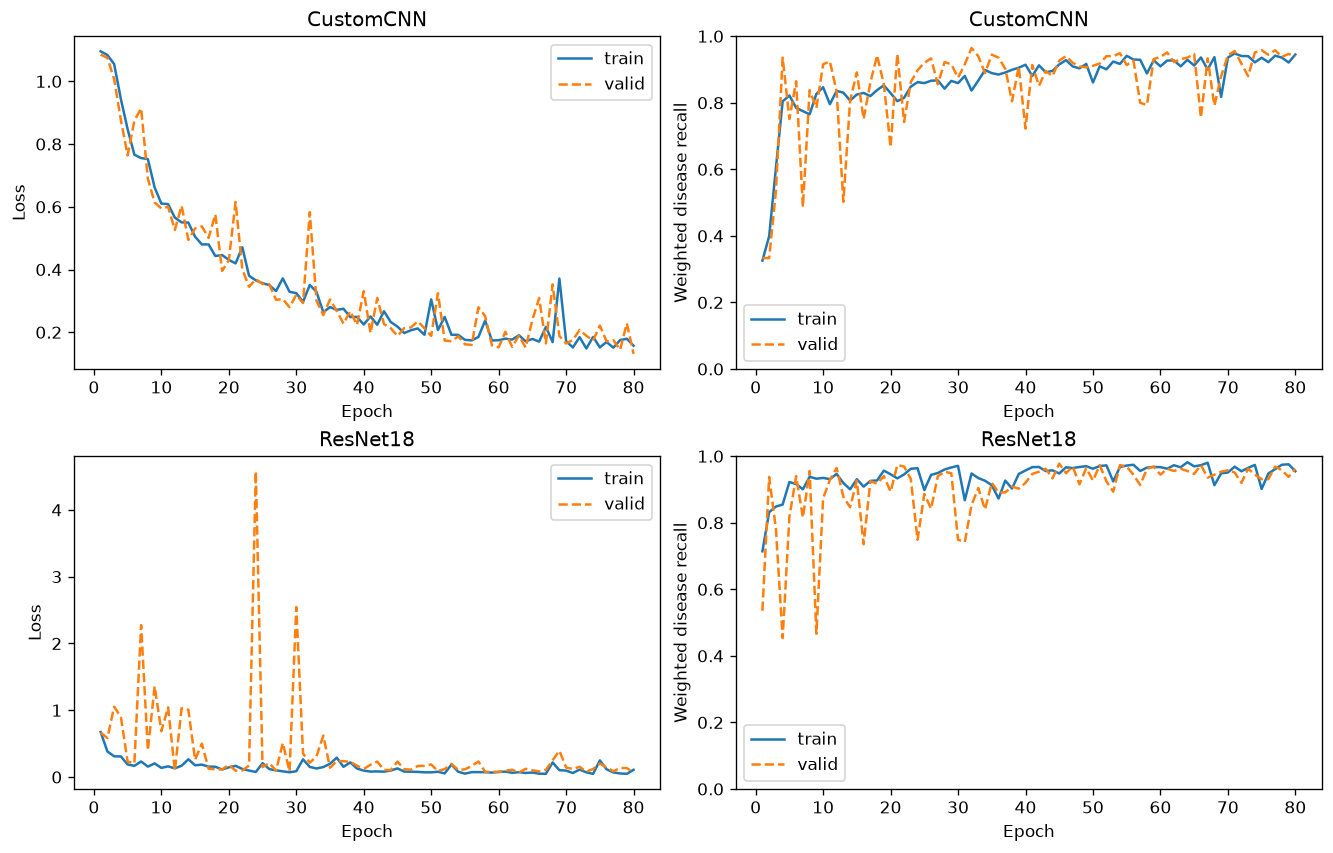

In [8]:
start = monotonic()
augmented_history = {model.__name__: fit(model, augment=True, alpha=alpha) for model in models}
plot_history(augmented_history)
print(f"Прогон с аугментацией: {monotonic() - start:.0f} с")


### Сравнение лучших эпох на валидации

Выбираем лучшую эпоху каждого прогона по взвешенному recall болезней. При равенстве сохраняем более раннюю эпоху.

### Сравнение моделей на валидации

Основная метрика — взвешенный recall болезней. Фитофтороз имеет вес 2, ранняя пятнистость — вес 1.

- **Recall диагноза** — доля правильно распознанных листьев среди всех листьев с этой болезнью.
- **Precision диагноза** — доля верных диагнозов среди всех предсказаний этого диагноза.
- **Ложные тревоги** — доля здоровых листьев, которым модель поставила любой из двух диагнозов. На столбцах указано число таких листьев из общего числа здоровых.

При обучении сохраняем эпоху с максимальным взвешенным recall на валидации. При равенстве выбираем более раннюю эпоху.


Модель | Прогон | Лучшая эпоха | Взвешенный recall (α=2)
CustomCNN | Без аугментаций | 75 | 96.44%
CustomCNN | С аугментациями | 32 | 96.44%
ResNet18 | Без аугментаций | 42 | 98.22%
ResNet18 | С аугментациями | 45 | 97.78%


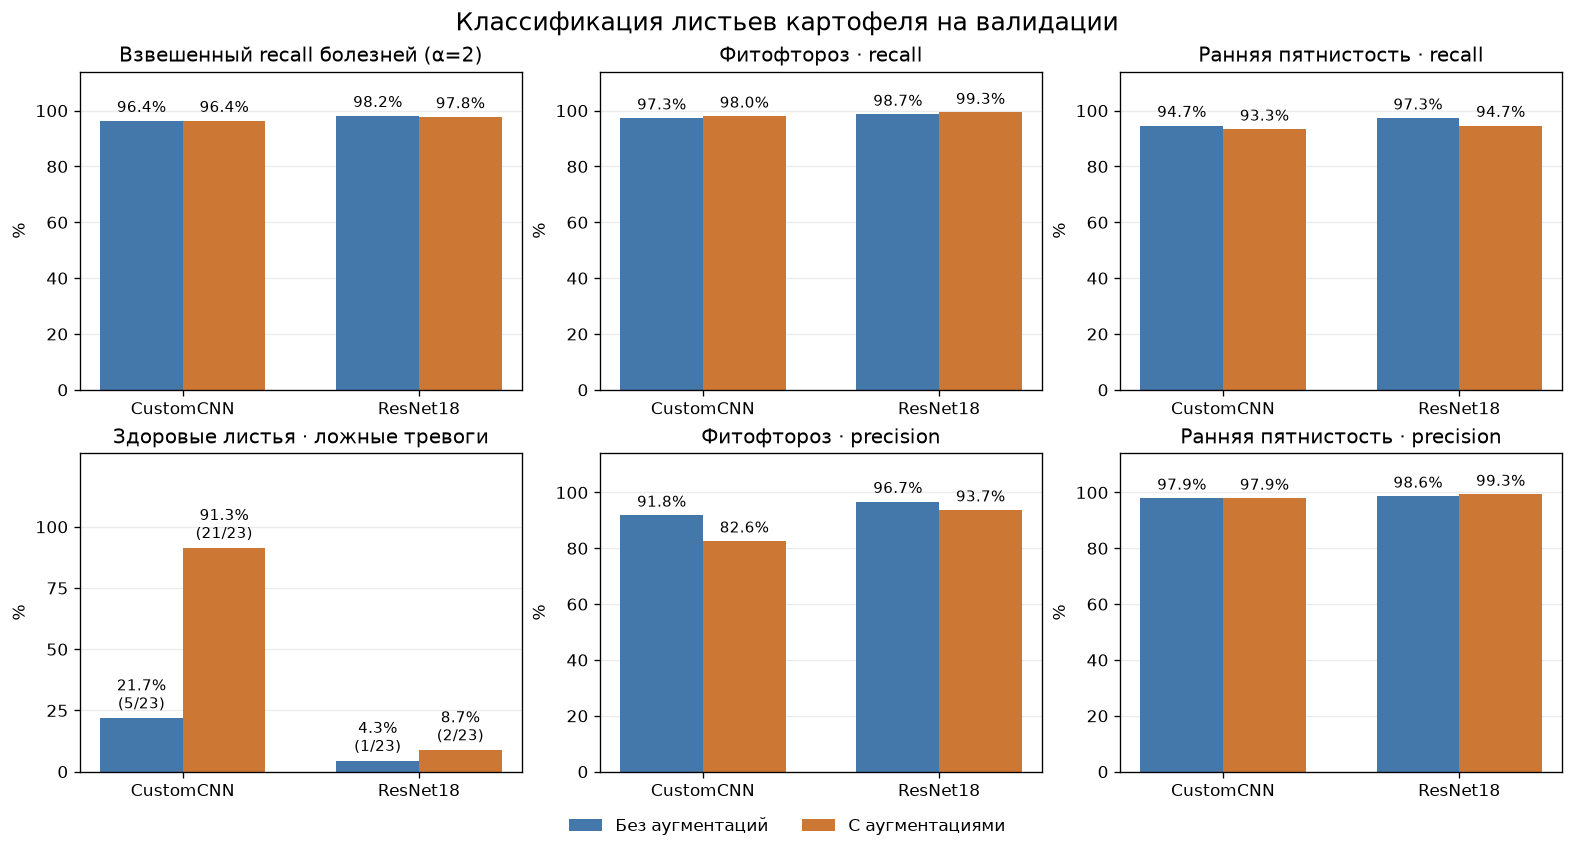

In [9]:
print(f"Модель | Прогон | Лучшая эпоха | Взвешенный recall (α={alpha})")
results = {}
runs = {"baseline": "Без аугментаций", "augmented": "С аугментациями"}

for model_class in models:
    for run, run_label in runs.items():
        model = model_class(num_classes=num_classes).to(device)
        checkpoint = checkpoint_dir / f"{model_class.__name__}_{run}.pt"
        saved = torch.load(checkpoint, map_location=device, weights_only=True)
        model.load_state_dict(saved["weights"])
        model.eval()

        # Строка матрицы — истинный класс, столбец — предсказанный.
        matrix = torch.zeros((num_classes, num_classes), dtype=torch.long, device=device)
        with torch.inference_mode():
            for x, y in val_loader:
                predicted = model(x.to(device).float() / 255).argmax(dim=1)
                pairs = y.to(device) * num_classes + predicted
                matrix += torch.bincount(pairs, minlength=num_classes ** 2).reshape_as(matrix)

        correct = matrix.diag()
        recall = (correct / matrix.sum(dim=1)).tolist()
        precision = (correct / matrix.sum(dim=0).clamp_min(1)).tolist()
        weighted_recall = weighted_disease_recall(recall, alpha)
        healthy = matrix[1].sum().item()
        false_alarms = healthy - correct[1].item()

        results[model_class.__name__, run] = (
            weighted_recall, recall[2], recall[0],
            false_alarms / healthy, precision[2], precision[0],
        ), f"{false_alarms}/{healthy}"
        best_epoch = saved["epoch"]
        print(f"{model_class.__name__} | {run_label} | {best_epoch} | {weighted_recall:.2%}")

fig, axes = plt.subplots(2, 3, figsize=(13, 7), layout="constrained")
fig.suptitle("Классификация листьев картофеля на валидации", fontsize=15)
titles = [
    f"Взвешенный recall болезней (α={alpha})",
    "Фитофтороз · recall",
    "Ранняя пятнистость · recall",
    "Здоровые листья · ложные тревоги",
    "Фитофтороз · precision",
    "Ранняя пятнистость · precision",
]
names = [model_class.__name__ for model_class in models]
positions = np.arange(len(names))
width = 0.35

for metric, (ax, title) in enumerate(zip(axes.flat, titles)):
    for (run, run_label), offset, color in zip(runs.items(), (-width / 2, width / 2), ("#4477AA", "#CC7733")):
        rows = [results[name, run] for name in names]
        values = [metrics[metric] * 100 for metrics, _ in rows]
        bars = ax.bar(positions + offset, values, width, color=color, label=run_label)
        if metric == 3:
            annotations = [f"{value:.1f}%\n({count})" for value, (_, count) in zip(values, rows)]
        else:
            annotations = [f"{value:.1f}%" for value in values]
        ax.bar_label(bars, labels=annotations, padding=3, fontsize=9)

    ax.set_xticks(positions, names)
    ax.set(title=title, ylim=(0, 114), yticks=range(0, 101, 20), ylabel="%")
    ax.set_axisbelow(True)
    ax.grid(axis="y", alpha=0.25)

# У ложных тревог отдельный масштаб, чтобы были видны малые доли.
max_false_alarms = max(metrics[3] * 100 for metrics, _ in results.values())
alarm_limit = min(100, max(20, 10 * (int(max_false_alarms / 10) + 1)))
axes[1, 0].set(ylim=(0, alarm_limit * 1.3), yticks=range(0, alarm_limit + 1, alarm_limit // 4))
handles, legend_labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, legend_labels, loc="outside lower center", ncols=2, frameon=False)
plt.show()


Вывод: 

1) если смотреть на resnet, то взвешанный recal не изменился. Но конкретно по своя Фитофтороз recall повысился, а recal по ранней пятнистости уменьшился. Для нашей задачи это лучше, тк Фитофтороз опаснее для нашей картошки, чем рання пятнистость


2) своя cnn по взвешанному recall слабо отличается от resnet. Хотя слоев 3 и 18 соотвественно. и скорость в 4 раза быстрее у своего cnn. Однако, ложные срабатывания сильно уменьшились у resnet. Можно сказать, что если очень важна скорост работы, стоит брать нашу реализация cnn. Если важно чуть лучше угадывать болезни и в 10 раз реже ложно срабатывать на здоровых листьях, то берем resnet18

### 2.1. Валидация модели классификации



ResNet18 | С аугментациями | эпоха 45 | тест: 323 листа
Взвешенный recall болезней (α=2) — 97.33%


| Истинный класс | Изображений в тесте | Recall | Precision |
| --- | ---: | ---: | ---: |
| Ранняя пятнистость | 150 | 96.00% | 98.63% |
| Здоровый лист | 23 | 95.65% | 95.65% |
| Фитофтороз | 150 | 98.00% | 95.45% |

Ложные тревоги на здоровых листьях — 1/23 (4.35%)


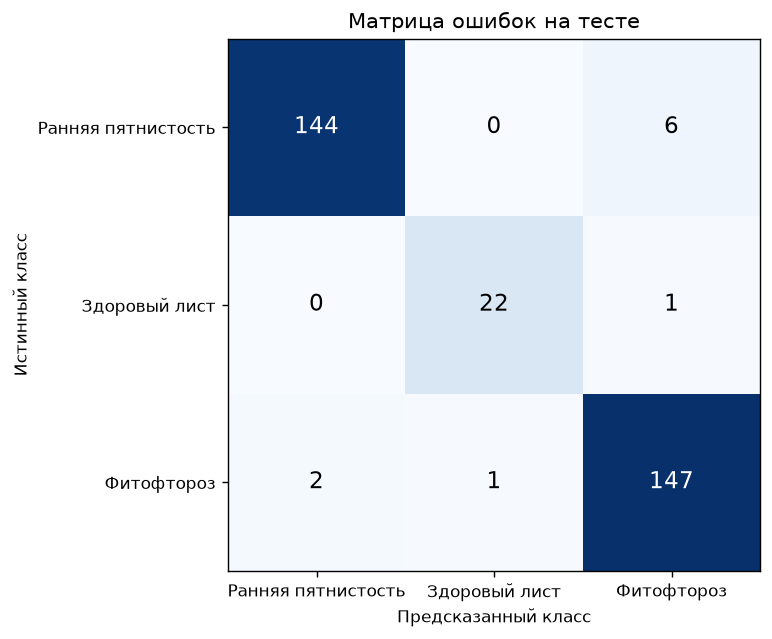

In [10]:
best_name, best_run = "ResNet18", "augmented"
best_model_class = ResNet18
checkpoint = checkpoint_dir / f"{best_name}_{best_run}.pt"
saved = torch.load(checkpoint, map_location=device, weights_only=True)
model = best_model_class(num_classes=num_classes).to(device)
model.load_state_dict(saved["weights"])
model.eval()

test_data = TensorDataset(images[test_ids], targets[test_ids])
test_loader = DataLoader(test_data, batch_size=batch_size)
test_matrix = torch.zeros((num_classes, num_classes), dtype=torch.long, device=device)

with torch.inference_mode():
    for x, y in test_loader:
        predicted = model(x.to(device).float() / 255).argmax(dim=1)
        # Кодируем пару (истинный класс, предсказанный класс) одним индексом.
        pairs = y.to(device) * num_classes + predicted
        test_matrix += torch.bincount(pairs, minlength=num_classes ** 2).reshape_as(test_matrix)

correct = test_matrix.diag()
recall = (correct / test_matrix.sum(dim=1)).tolist()
precision = (correct / test_matrix.sum(dim=0).clamp_min(1)).tolist()
healthy = test_matrix[1].sum().item()
false_alarms = healthy - correct[1].item()

print(f"{best_name} | {runs[best_run]} | эпоха {saved['epoch']} | тест: {len(test_data)} листа")
print(f"Взвешенный recall болезней (α={alpha}) — {weighted_disease_recall(recall, alpha):.2%}")

class_names = list(labels.values())
metrics_table = [
    "| Истинный класс | Изображений в тесте | Recall | Precision |",
    "| --- | ---: | ---: | ---: |",
]
test_counts = test_matrix.sum(dim=1).tolist()
for name, count, r, p in zip(class_names, test_counts, recall, precision):
    metrics_table.append(f"| {name} | {count} | {r:.2%} | {p:.2%} |")
display(Markdown("\n".join(metrics_table)))

print(f"Ложные тревоги на здоровых листьях — {false_alarms}/{healthy} ({false_alarms / healthy:.2%})")

# Строки соответствуют истинным классам, столбцы — предсказаниям.
counts = test_matrix.cpu().numpy()
fig, ax = plt.subplots(figsize=(8, 5), layout="constrained")
ax.imshow(counts, cmap="Blues", vmin=0)
ax.set_xticks(range(num_classes), class_names)
ax.set_yticks(range(num_classes), class_names)
ax.set(xlabel="Предсказанный класс", ylabel="Истинный класс", title="Матрица ошибок на тесте")
for row in range(num_classes):
    for column in range(num_classes):
        count = counts[row, column]
        color = "white" if count > counts.max() / 2 else "black"
        ax.text(column, row, str(count), ha="center", va="center", color=color, fontsize=13)
plt.show()


## 3. Замена большой свёртки меньшими

Применим маленькие свёртки к матрицам 15×15, 75×75 и 6×6. Каждый раз обрабатываем результат предыдущего слоя, пока не останется одно число. Считаем, сколько применений потребовалось.


Берём один входной и один выходной канал, шаг 1, без padding, bias и активаций. Веса ядра одинаковые и вычисляют среднее окна. Промежуточные карты уменьшаются. Все веса ненулевые, поэтому последнее число зависит от всей исходной матрицы: её размер и есть итоговое рецептивное поле.

Для 6×6, когда останется матрица 2×2, применим ядро 2×2. Только ядрами 3×3 получить нужное поле 6×6 при шаге 1 нельзя.


In [1]:
def small_convolutions(size):
    matrix = torch.arange(1, size * size + 1, dtype=torch.float64).reshape(1, 1, size, size)
    kernels = []
    parameters = operations = 0
    print(f"Исходная матрица: {size}×{size}")

    with torch.no_grad():
        while matrix.shape[-1] > 1:
            kernel = 3 if matrix.shape[-1] >= 3 else 2
            conv = nn.Conv2d(1, 1, kernel, bias=False).double()
            conv.weight.fill_(1 / conv.weight.numel())  # считаем среднее окна
            matrix = conv(matrix)

            kernels.append(kernel)
            parameters += conv.weight.numel()
            operations += matrix.numel() * conv.weight.numel()  # число умножений этого слоя
            side = matrix.shape[-1]
            print(f"Шаг {len(kernels)}: ядро {kernel}×{kernel} → матрица {side}×{side}")

    print(f"Итого: {len(kernels)} применений; рецептивное поле {size}×{size}")
    print(f"Последнее число: {matrix.item():.4f}")
    return kernels, parameters, operations


### Сначала проверим ядро 15×15

Числа в исходной матрице идут от 1 до 225 по строкам. Ядра усредняющие, поэтому можно выполнить расчёт без обучения сети.


In [2]:
result_15 = small_convolutions(15)


Исходная матрица: 15×15
Шаг 1: ядро 3×3 → матрица 13×13
Шаг 2: ядро 3×3 → матрица 11×11
Шаг 3: ядро 3×3 → матрица 9×9
Шаг 4: ядро 3×3 → матрица 7×7
Шаг 5: ядро 3×3 → матрица 5×5
Шаг 6: ядро 3×3 → матрица 3×3
Шаг 7: ядро 3×3 → матрица 1×1
Итого: 7 применений; рецептивное поле 15×15
Последнее число: 113.0000


### Затем проверим ядра 75×75 и 6×6


In [3]:
result_75 = small_convolutions(75)
result_6 = small_convolutions(6)


Исходная матрица: 75×75
Шаг 1: ядро 3×3 → матрица 73×73
Шаг 2: ядро 3×3 → матрица 71×71
Шаг 3: ядро 3×3 → матрица 69×69
Шаг 4: ядро 3×3 → матрица 67×67
Шаг 5: ядро 3×3 → матрица 65×65
Шаг 6: ядро 3×3 → матрица 63×63
Шаг 7: ядро 3×3 → матрица 61×61
Шаг 8: ядро 3×3 → матрица 59×59
Шаг 9: ядро 3×3 → матрица 57×57
Шаг 10: ядро 3×3 → матрица 55×55
Шаг 11: ядро 3×3 → матрица 53×53
Шаг 12: ядро 3×3 → матрица 51×51
Шаг 13: ядро 3×3 → матрица 49×49
Шаг 14: ядро 3×3 → матрица 47×47
Шаг 15: ядро 3×3 → матрица 45×45
Шаг 16: ядро 3×3 → матрица 43×43
Шаг 17: ядро 3×3 → матрица 41×41
Шаг 18: ядро 3×3 → матрица 39×39
Шаг 19: ядро 3×3 → матрица 37×37
Шаг 20: ядро 3×3 → матрица 35×35
Шаг 21: ядро 3×3 → матрица 33×33
Шаг 22: ядро 3×3 → матрица 31×31
Шаг 23: ядро 3×3 → матрица 29×29
Шаг 24: ядро 3×3 → матрица 27×27
Шаг 25: ядро 3×3 → матрица 25×25
Шаг 26: ядро 3×3 → матрица 23×23
Шаг 27: ядро 3×3 → матрица 21×21
Шаг 28: ядро 3×3 → матрица 19×19
Шаг 29: ядро 3×3 → матрица 17×17
Шаг 30: ядро 3×3 → матрица 1

### Вывод формулы 


Обозначим через $R_l$ сторону рецептивного поля одного элемента после $l$ свёрток. Поле $R_l=15$ означает область 15×15 исходной матрицы. До свёрток каждый элемент зависит только от самого себя, поэтому $R_0=1$.

Рассматриваем условия эксперимента: шаг 1, dilation 1, без padding.


**Почему поле увеличивается.** Ядро 3×3 берёт три соседних элемента по каждой оси. На первом слое они охватывают три исходных пикселя. На следующем слое три соседние области ширины 3 перекрываются и вместе охватывают 5 пикселей:

```text
первый элемент:   1 2 3
второй элемент:     2 3 4
третий элемент:       3 4 5
вместе:          1 2 3 4 5
```

По вертикали происходит то же самое, поэтому поле второго слоя — 5×5.


**Переход к произвольному ядру.** При шаге 1 соседние области смещены на один исходный пиксель. Объединение $k_l$ таких областей расширяет сторону поля на $k_l-1$:

$$R_l=R_{l-1}+(k_l-1).$$

Здесь $k_l$ — сторона ядра слоя $l$. Раскрывая выражение от $R_0=1$, получаем для $L$ слоёв:

$$R_L=1+\sum_{l=1}^{L}(k_l-1).$$


**Если все ядра одинаковые.** При $k_l=k$ каждое применение добавляет $k-1$:

$$R_L=1+L(k-1),\qquad L=\frac{R_L-1}{k-1}.$$

Для ядер 3×3:

$$R_L=1+2L,\qquad L=\frac{R_L-1}{2}.$$

Число слоёв $L$ должно быть целым. Поэтому только ядрами 3×3 можно получить нечётное поле, а для поля 6×6 понадобится также чётное ядро.


### Сопоставление формулы с экспериментом

| Нужное поле | Вычисление по формуле | Результат выполнения кода |
| --- | --- | --- |
| 15×15 | $L=(15-1)/2=7$, $R=1+7\cdot2=15$ | 7 свёрток 3×3, матрица 15×15 уменьшилась до 1×1 |
| 75×75 | $L=(75-1)/2=37$, $R=1+37\cdot2=75$ | 37 свёрток 3×3, матрица 75×75 уменьшилась до 1×1 |
| 6×6 | $R=1+(3-1)+(3-1)+(2-1)=6$ | 3 свёртки: 3×3 → 3×3 → 2×2; размеры матриц: 6 → 4 → 2 → 1 |

Формула дала то же число применений и то же итоговое рецептивное поле, что и эксперимент.


**Связь с напечатанными размерами матриц.** Для входа 15×15 код напечатал:

| Число применений 3×3 | 0 | 1 | 2 | 3 | 4 | 5 | 6 | 7 |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| Сторона оставшейся матрицы | 15 | 13 | 11 | 9 | 7 | 5 | 3 | 1 |
| Сторона рецептивного поля $R_L$ | 1 | 3 | 5 | 7 | 9 | 11 | 13 | 15 |

Размер карты уменьшается, а область исходной матрицы, влияющая на один её элемент, увеличивается. Последнее число зависит от всей области 15×15 — как результат одной свёртки 15×15. Равенство полей не гарантирует равенства выходных значений.


### Сравнение числа параметров и умножений

Число параметров — число весов всех ядер (без bias). Для каждого выходного элемента выполняется по одному умножению на каждый вес ядра. Складываем число умножений всех слоёв, включая промежуточные карты. Сложения отдельно не считаем.

Одна большая свёртка обрабатывает ту же исходную матрицу и сразу выдаёт одно число. Сравниваем отдельные обучаемые веса каждого слоя; в эксперименте они просто заполнены одинаковыми значениями.


In [4]:
table = [
    "| Большое ядро | Маленькие ядра по шагам | Применений | Число параметров: до → после | Число умножений: до → после |",
    "| --- | --- | ---: | ---: | ---: |",
]

for size, (kernels, parameters, operations) in zip((15, 75, 6), (result_15, result_75, result_6)):
    big_kernel = torch.ones(1, 1, size, size)
    big_parameters = big_kernel.numel()
    big_operations = big_parameters  # у большой свёртки одна выходная позиция
    replacement = f"{len(kernels)} слоя 3×3" if size != 6 else "3×3 → 3×3 → 2×2"
    table.append(
        f"| {size}×{size} | {replacement} | {len(kernels)} | "
        f"{big_parameters} → {parameters} | {big_operations} → {operations} |"
    )
    print(f"Ядро {size}: параметров меньше в {big_parameters / parameters:.2f} раза, "
          f"умножений больше в {operations / big_operations:.2f} раза")

display(Markdown("\n".join(table)))


Ядро 15: параметров меньше в 3.57 раза, умножений больше в 18.20 раза
Ядро 75: параметров меньше в 16.89 раза, умножений больше в 108.04 раза
Ядро 6: параметров меньше в 1.64 раза, умножений больше в 5.11 раза


| Большое ядро | Маленькие ядра по шагам | Применений | Число параметров: до → после | Число умножений: до → после |
| --- | --- | ---: | ---: | ---: |
| 15×15 | 7 слоя 3×3 | 7 | 225 → 63 | 225 → 4095 |
| 75×75 | 37 слоя 3×3 | 37 | 5625 → 333 | 5625 → 607725 |
| 6×6 | 3×3 → 3×3 → 2×2 | 3 | 36 → 22 | 36 → 184 |

**Наблюдение.** Для поля 15×15 понадобилось 7 свёрток 3×3, для 75×75 — 37. Для поля 6×6 понадобились две свёртки 3×3 и одна 2×2. На каждом шаге можно проследить размер оставшейся матрицы.


В этом эксперименте число параметров уменьшилось, а число умножений увеличилось: большая свёртка выдаёт только одно число, а маленькие сначала вычисляют промежуточные карты. При padding, сохраняющем размеры карт, сравнение операций будет другим.



## 4. Эквивариантность свёрточного преобразования

Докажем эквивариантность относительно сдвига для двумерного изображения: если сначала сдвинуть изображение, а затем применить свёртку, получим тот же результат, что и при сдвиге готовой карты признаков. Ядро в обоих случаях одинаковое.


### Размеры изображения и выходной карты

Пусть изображение $X$ имеет размер $N\times N$. Его элементы нумеруются так:

$$X(p,q),\qquad p,q=0,\ldots,N-1.$$

Применяем ядро $K$ размера $k\times k$, где $1<k\le N$, с шагом 1 и без padding. Сторону выходной карты обозначим через $M$:

$$M=N-k+1<N.$$

Поэтому у выхода меньше допустимых индексов:

$$Y(i,j),\qquad i,j=0,\ldots,M-1.$$

Например, при $N=5$, $k=3$ имеем $M=3$: входные индексы идут от 0 до 4, выходные — от 0 до 2.


### Как вычисляется элемент выхода

Каждое положение ядра даёт одно число карты признаков:

$$Y(i,j)=\sum_{u=0}^{k-1}\sum_{v=0}^{k-1}K(u,v)X(i+u,j+v),\qquad 0\le i,j<M.$$

Здесь $i,j$ задают позицию выходного элемента и левый верхний угол окна на входе. Индексы $u,v$ перебирают элементы внутри ядра. При перемещении окна получаем всю карту $M\times M$.

В последнем окне максимальный индекс входа равен

$$(M-1)+(k-1)=N-1.$$

Значит, окно не выходит за границы изображения.


### Сдвиг изображения

Сдвинем содержимое изображения на $a$ пикселей вниз и $b$ вправо. Новое изображение обозначим $\widetilde X$:

$$\widetilde X(p,q)=X(p-a,q-b).$$

В новую позицию приходит пиксель из прежней позиции выше и левее. Например, при сдвиге на одну строку вниз и один столбец вправо:

$$\widetilde X(2,3)=X(1,2).$$

Размер массива остаётся $N\times N$. Формулу используем там, где исходные индексы допустимы; вновь открывшиеся края можно заполнить нулями. Равенство доказываем для окон, которые целиком сохранились при сдвиге.


### Сначала сдвиг, затем свёртка

Применим то же ядро к сдвинутому изображению. Выход $\widetilde Y$ также имеет размер $M\times M$:

$$\widetilde Y(i,j)=\sum_{u=0}^{k-1}\sum_{v=0}^{k-1}K(u,v)\widetilde X(i+u,j+v).$$

Подставим определение сдвига:

$$\widetilde X(i+u,j+v)=X(i+u-a,j+v-b).$$

Получаем:

$$\boxed{\widetilde Y(i,j)=\sum_{u=0}^{k-1}\sum_{v=0}^{k-1}K(u,v)X(i+u-a,j+v-b).}$$


### Сначала свёртка, затем сдвиг

Возьмём обычную карту $Y$ и сдвинем её на те же $a,b$. В позиции $(i,j)$ окажется прежнее значение $Y(i-a,j-b)$. Распишем его:

$$Y(i-a,j-b)=\sum_{u=0}^{k-1}\sum_{v=0}^{k-1}K(u,v)X((i-a)+u,(j-b)+v).$$

Поскольку $(i-a)+u=i+u-a$ и $(j-b)+v=j+v-b$, получаем:

$$\boxed{Y(i-a,j-b)=\sum_{u=0}^{k-1}\sum_{v=0}^{k-1}K(u,v)X(i+u-a,j+v-b).}$$


### Сопоставление результатов

Выражения в рамках одинаковые. Следовательно,

$$\boxed{\widetilde Y(i,j)=Y(i-a,j-b).}$$

Для конечных карт равенство рассматриваем в общей допустимой области:

$$0\le i,j<M,\qquad 0\le i-a,j-b<M.$$

При $a,b\ge0$ это означает $a\le i<M$, $b\le j<M$. В этой области все сравниваемые окна исходного изображения сохранены.


**Вывод.** Сдвиг изображения вызывает такой же сдвиг карты признаков в общей допустимой области. Размер карты меньше размера изображения ($M<N$), но при шаге 1 перемещение окна на один пиксель соответствует перемещению на одну позицию выхода.

Использована запись свёрточной операции как в `Conv2d` (взаимная корреляция), с фиксированным ядром и шагом 1. Для математической свёртки доказательство аналогично. На бесконечной сетке равенство выполняется всюду; для конечного изображения обрезание и обработку границ необходимо учитывать отдельно.


### Интерактивная проверка эквивариантности

Меняем сдвиг по строкам и столбцам и сравниваем два порядка действий. В общей допустимой области нижние матрицы совпадают. Заштрихованные клетки находятся вне области доказательства.

Для отображения выполните следующую ячейку. Если Jupyter блокирует интерактивный вывод, отметьте ноутбук как доверенный (Trust Notebook).


In [ ]:
interactive_source = Path("output/shift-equivariance.html").read_text(encoding="utf-8")

# оформление схемы для отображения внутри Jupyter
interactive_styles = """
:root {
    color-scheme: light dark;
    --font-size-base: 14px;
    --foreground: #202124; --muted-foreground: #555;
    --muted: #e8e8ec; --viz-series-1: #2463b6;
}
body { font-family: sans-serif; margin: 12px; }
h3 { font-size: 14px; font-weight: 500; margin: 0; }
.form-range { width: 100%; }
.text-small { font-size: 12px; }
.tabular-nums { font-variant-numeric: tabular-nums; }
@media (prefers-color-scheme: dark) {
    :root { --foreground: #eee; --muted-foreground: #bbb;
            --muted: #35353e; --viz-series-1: #82b5ff; }
}
"""
interactive_page = (
    '<!doctype html><html lang="ru"><meta charset="utf-8">'
    '<meta name="viewport" content="width=device-width, initial-scale=1">'
    f'<style>{interactive_styles}</style><body>{interactive_source}</body></html>'
)
display(HTML(
    f'<iframe title="Проверка эквивариантности свёртки" '
    f'srcdoc="{escape(interactive_page, quote=True)}" '
    'style="width:100%;height:1150px;border:0" sandbox="allow-scripts"></iframe>'
))


Интерактивная проверка эквивариантности

**Замечание о границах.** Заштрихованные края двух карт могут различаться: слева свёртка обрабатывает окна с добавленными при сдвиге нулями, справа нулями заполняется край уже готовой карты признаков. Эквивариантность здесь проверяется только в общей допустимой области без штриховки, где значения совпадают.
